#### Background

Diffusion in a fluid can be modeled using a lattice model, in which molecules are treated as sitting on fixed lattice sites in space. We will simulate two particles that freely diffuse on a lattice. Particle moves are governed by 

$$
\frac{p_i}{p_j} = \text{exp}\left(-\frac{\Delta E}{RT}\right)
$$

where
the difference in energy between the two states is $\Delta E = E_i - E_j$. The energy decreases by $\sigma$ when the two particles are next to each other, otherwise the energy is zero.

The acceptance criterion for transitions from $i$ to $j$ is 

$$
p_{acc} = \text{min} \left(1,\text{exp}\left(\frac{ - \Delta E}{RT}\right) \right)
$$

#### Instructions

Adapt the lattice model we developed in class to model the diffusion of $N$ = 2 particles in a 1D lattice with 100 sites at $RT/\sigma$ = 0.5. Use periodic boundary conditions. To avoid bias, choose the particle randomly for each move.
 - Use and report a random 32-bit seed.
 - Plot the energy vs the number of sweeps.
 - Track and report the move acceptance ratio and the number of transtions from two monomers to one dimer.
 - Determine the equilibrium population of dimers by attempting to move each molecule $N_{sweeps}$ = 10,000 times. 
 
#### Sample Output

Sample output, for different parameters, is:

```
seed = 5937865198091435522

Number of Lattice Sites: 10
Number of Particles: 2
Temperature: 1.0

Number of Accepts:         128175
Number of Moves:           200000
Acceptance Ratio:           0.641

Number of Transitions:      32060
Dimer Population:           0.439 +/- 0.00157
```

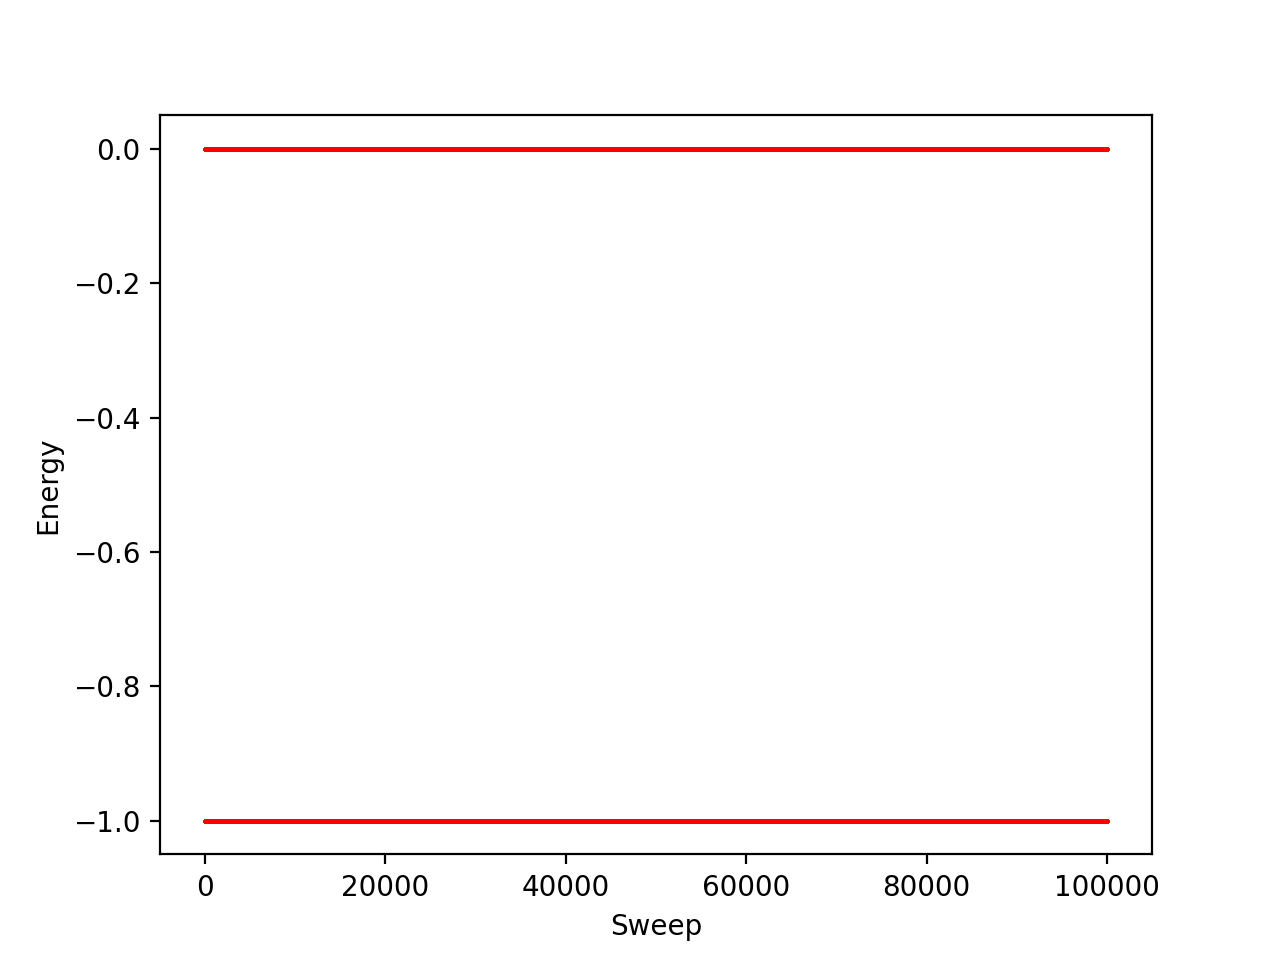

In [1]:
import numpy as np
import matplotlib.pyplot as plt
seed = np.random.default_rng().integers(int(2**63))
print('seed = %d' % seed)
rng = np.random.default_rng(seed=seed)

seed = 8550530493380151254


8550530493380151254
Number of Lattice Sites: 100
Number of particles: 2
Temperature: 1

Number of accepts: 100
Number of moves: 100
Acceptance Ratio: 1.0
Number of Transitions: 100 +/- 0
Dimer Population: 0


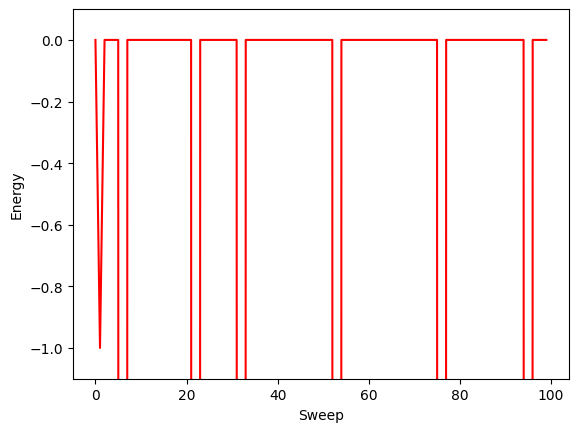

In [22]:
# lattice parameters
nLat = 101

# dimensionless parameters
RT = 0.5
sigma = 1
N = 2

# simulation parameters
nTrials = 100  ## Takes forever with 10,000 ## Was not able to get code to fully work properly ##

# main code
nMoves = [] # hold results from each trial
E_record = []
E=0

for iTrial in range(nTrials):

    # reset lattice
    lattice = np.zeros(nLat,dtype=bool)
        
    # reset free particle
    coord1 = rng.integers(0,nLat-1)   #randomly locating the particles
    coord2 = rng.integers(0,nLat-1)

    lattice[coord1] = 1
    lattice[coord2] = 1
 
    E = 0
    iMoves = 0
    Accepts = 0
    Dimers = 0

    for i in range(nTrials):
        coord = rng.choice([coord1,coord2]) #randomly choosing a particle to move
        iMoves += 1
        old = coord
        # pick a new state
        iDir = rng.choice([-1,1])
        new = (old + iDir) % nLat
        nabor = (new + iDir) % nLat
        dE = -sigma * lattice[nabor]
        lnPacc = -dE / RT
        # accept or reject
        if lnPacc > 0 or rng.random() < np.exp(lnPacc):
            accept = True
        else:
            accept = False
        # update
        if accept:
            E += dE

            if E < 0:
                Dimers +=1
            
            Accepts += 1
            lattice[new] = 1
            lattice[old] = 0
            coord = new
    # record
    nMoves.append(iMoves)
    E_record.append(E)


# output
print(seed)
print('Number of Lattice Sites:', nLat-1)
print('Number of particles:', N)
print('Temperature:', sigma)
print()
print('Number of accepts:', Accepts)
print('Number of moves:', len(nMoves))
print('Acceptance Ratio:', Accepts/len(nMoves))


avg = np.average(nMoves)
std = np.std(nMoves)/np.sqrt(nTrials)
print(f'Number of Transitions: {avg:.0f} +/- {std:.0f}')
print(f'Dimer Population: {Dimers:.0f}')
plt.plot(E_record,'r-')
plt.ylim(-1.1,0.1)
plt.xlabel("Sweep")
plt.ylabel("Energy")
plt.show()
